# Another Go

In [1]:
import torch

torch.cuda.empty_cache()  # Frees unused memory
torch.cuda.ipc_collect()  # Collects shared memory

### Initial Setup:

In [ ]:
import os  # Import first to avoid TF auto-initialization

# Set TensorFlow to avoid pre-initializing GPUs
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"

import tensorflow as tf

# GPU Setup (Must be before any TF operation)
physical_devices = tf.config.list_physical_devices('GPU')
if physical_devices:
    for device in physical_devices:
        tf.config.experimental.set_memory_growth(device, True)

# Import Keras mixed precision after GPU setup
from tensorflow.keras import mixed_precision

# Enable mixed precision
tf.keras.mixed_precision.set_global_policy('float32')

print("GPU memory growth set successfully!")

In [3]:
from tensorflow.keras.metrics import Metric
from tensorflow.keras import backend as K
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.metrics import Precision, Recall

class Precision(Metric):
    def __init__(self, name='precision', **kwargs):
        super(Precision, self).__init__(name=name, **kwargs)
        self.true_positives = self.add_weight(name='tp', initializer='zeros')
        self.false_positives = self.add_weight(name='fp', initializer='zeros')

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = K.flatten(y_true)
        y_pred = K.flatten(y_pred)
        y_pred = K.round(y_pred)  # Convert probabilities to binary predictions

        true_positives = K.sum(K.cast(y_true * y_pred, 'float'))
        false_positives = K.sum(K.cast((1 - y_true) * y_pred, 'float'))

        self.true_positives.assign_add(true_positives)
        self.false_positives.assign_add(false_positives)

    def result(self):
        precision = self.true_positives / (self.true_positives + self.false_positives + K.epsilon())
        return precision

    def reset_states(self):
        self.true_positives.assign(0)
        self.false_positives.assign(0)

class Recall(Metric):
    def __init__(self, name='recall', **kwargs):
        super(Recall, self).__init__(name=name, **kwargs)
        self.true_positives = self.add_weight(name='tp', initializer='zeros')
        self.false_negatives = self.add_weight(name='fn', initializer='zeros')

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = K.flatten(y_true)
        y_pred = K.flatten(y_pred)
        y_pred = K.round(y_pred)  # Convert probabilities to binary predictions

        true_positives = K.sum(K.cast(y_true * y_pred, 'float'))
        false_negatives = K.sum(K.cast(y_true * (1 - y_pred), 'float'))

        self.true_positives.assign_add(true_positives)
        self.false_negatives.assign_add(false_negatives)

    def result(self):
        recall = self.true_positives / (self.true_positives + self.false_negatives + K.epsilon())
        return recall

    def reset_states(self):
        self.true_positives.assign(0)
        self.false_negatives.assign(0)
        
# Define Dice Coefficient and IoU metrics
def dice_coef(y_true, y_pred, smooth=1):
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred)
    return (2.0 * intersection + smooth) / (union + smooth)

def iou(y_true, y_pred, smooth=1):
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)

### EfficientNetB4 BackBone

In [19]:
from tensorflow.keras.applications import EfficientNetB4
from tensorflow.keras import layers, models
import tensorflow as tf

def attention_gate(x, g, filters):
    """Attention gate to focus on relevant features"""
    theta_x = layers.Conv2D(filters, (1, 1), padding='same')(x)
    phi_g = layers.Conv2D(filters, (1, 1), padding='same')(g)
    
    # Addition followed by ReLU
    f = layers.Activation('relu')(layers.add([theta_x, phi_g]))
    
    # Channel-wise weights
    psi_f = layers.Conv2D(1, (1, 1), padding='same')(f)
    rate = layers.Activation('sigmoid')(psi_f)
    
    # Attention weighted features
    return layers.multiply([x, rate])

def unet_model(input_shape=(224, 224, 3)):
    base_model = EfficientNetB4(input_tensor=layers.Input(shape=input_shape), include_top=False, weights='imagenet')
    s1 = base_model.get_layer('block2a_expand_activation').output  # 112x112x24
    s2 = base_model.get_layer('block3a_expand_activation').output  # 56x56x32
    s3 = base_model.get_layer('block4a_expand_activation').output  # 28x28x56
    s4 = base_model.get_layer('block6a_expand_activation').output  # 14x14x160
    s5 = base_model.get_layer('top_activation').output             # 7x7x1792
    inputs = base_model.input
    
    # Stronger regularization
    kernel_regularizer = tf.keras.regularizers.l2(0.0001)
    
    # Bottleneck dropout
    x = layers.Dropout(0.5)(s5)
    
    # First upsampling block
    x = layers.Conv2DTranspose(160, (3, 3), strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    attention1 = attention_gate(s4, x, 160)
    x = layers.concatenate([x, attention1])
    x = layers.Conv2D(160, (3, 3), activation='relu', padding='same', kernel_regularizer=kernel_regularizer)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    
    # Second upsampling block
    x = layers.Conv2DTranspose(56, (3, 3), strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    attention2 = attention_gate(s3, x, 56)
    x = layers.concatenate([x, attention2])
    x = layers.Conv2D(56, (3, 3), activation='relu', padding='same', kernel_regularizer=kernel_regularizer)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    
    # Third upsampling block
    x = layers.Conv2DTranspose(32, (3, 3), strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    attention3 = attention_gate(s2, x, 32)
    x = layers.concatenate([x, attention3])
    x = layers.Conv2D(32, (3, 3), activation='relu', padding='same', kernel_regularizer=kernel_regularizer)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    # Fourth upsampling block
    x = layers.Conv2DTranspose(24, (3, 3), strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    attention4 = attention_gate(s1, x, 24)
    x = layers.concatenate([x, attention4])
    x = layers.Conv2D(24, (3, 3), activation='relu', padding='same', kernel_regularizer=kernel_regularizer)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.1)(x)
    
    # Final upsampling
    x = layers.Conv2DTranspose(16, (3, 3), strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(16, (3, 3), activation='relu', padding='same', kernel_regularizer=kernel_regularizer)(x)
    x = layers.BatchNormalization()(x)
    
    # Output layer
    outputs = layers.Conv2D(1, (1, 1), activation='sigmoid')(x)
    
    # Create and return model
    return models.Model(inputs, outputs)

### Enhanced ENetB4 Backbone Attention

#### Model Definition (B4 Residual)

In [8]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB4
import tensorflow.keras.backend as K

# Data augmentation function
def augment_data(image, mask):
    # Stack image and mask for joint transformations
    combined = tf.concat([image, mask], axis=-1)
    
    # Random horizontal flip
    if tf.random.uniform(()) > 0.5:
        combined = tf.image.flip_left_right(combined)
    
    # Random vertical flip
    if tf.random.uniform(()) > 0.5:
        combined = tf.image.flip_up_down(combined)
    
    # Random rotation (90 degree increments)
    k = tf.random.uniform(shape=[], minval=0, maxval=4, dtype=tf.int32)
    combined = tf.image.rot90(combined, k=k)
    
    # Separate image and mask
    image = combined[..., :-1]
    mask = combined[..., -1:]
    
    # Ensure image values are in valid range
    image = tf.clip_by_value(image, 0.0, 1.0)
    
    return image, mask

# Enhanced attention gate with regularization
def attention_gate(x, g, filters):
    """Enhanced attention gate with regularization"""
    l2_reg = tf.keras.regularizers.l2(0.0001)
    
    theta_x = layers.Conv2D(filters, (1, 1), padding='same', 
                           kernel_initializer='he_normal',
                           kernel_regularizer=l2_reg)(x)
    phi_g = layers.Conv2D(filters, (1, 1), padding='same', 
                         kernel_initializer='he_normal',
                         kernel_regularizer=l2_reg)(g)
    
    f = layers.add([theta_x, phi_g])
    f = layers.BatchNormalization()(f)
    f = layers.Activation('relu')(f)
    
    # # Spatial dropout for better generalization
    f = layers.SpatialDropout2D(0.1)(f)
    
    psi_f = layers.Conv2D(1, (1, 1), padding='same', 
                         kernel_initializer='he_normal',
                         kernel_regularizer=l2_reg)(f)
    rate = layers.Activation('sigmoid')(psi_f)
    
    return layers.multiply([x, rate])

# Residual decoder block
def residual_decoder_block(inputs, skip_features, filters, dropout_rate=0.2):
    """Decoder block with residual connection"""
    l2_reg = tf.keras.regularizers.l2(0.0001)
    
    # Upsampling
    x = layers.Conv2DTranspose(filters, (3, 3), strides=2, padding='same', 
                              kernel_initializer='he_normal', 
                              kernel_regularizer=l2_reg)(inputs)
    x = layers.BatchNormalization()(x)
    
    # Attention gate
    att = attention_gate(skip_features, x, filters)
    x = layers.concatenate([x, att])
    
    # First convolution
    x1 = layers.Conv2D(filters, (3, 3), padding='same', 
                     kernel_initializer='he_normal', 
                     kernel_regularizer=l2_reg)(x)
    x1 = layers.BatchNormalization()(x1)
    x1 = layers.Activation('relu')(x1)
    x1 = layers.SpatialDropout2D(dropout_rate)(x1)
    
    # Second convolution
    x2 = layers.Conv2D(filters, (3, 3), padding='same', 
                     kernel_initializer='he_normal', 
                     kernel_regularizer=l2_reg)(x1)
    x2 = layers.BatchNormalization()(x2)
    
    # 1x1 conv on the input to match dimensions for the residual connection
    shortcut = layers.Conv2D(filters, (1, 1), padding='same',
                           kernel_initializer='he_normal',
                           kernel_regularizer=l2_reg)(x)
    shortcut = layers.BatchNormalization()(shortcut)
    
    # Add residual connection
    x = layers.add([x2, shortcut])
    x = layers.Activation('relu')(x)
    
    return x

def improved_unet_model(input_shape=(224, 224, 3), dropout_rate=0.35):
    """Improved U-Net with EfficientNetB4 backbone, residual connections and attention"""
    # Use EfficientNetB4 as backbone
    base_model = EfficientNetB4(input_tensor=layers.Input(shape=input_shape), include_top=False, weights='imagenet')
    
    # Extract features at different scales
    s1 = base_model.get_layer('block2a_expand_activation').output  # 112x112
    s2 = base_model.get_layer('block3a_expand_activation').output  # 56x56
    s3 = base_model.get_layer('block4a_expand_activation').output  # 28x28
    s4 = base_model.get_layer('block6a_expand_activation').output  # 14x14
    s5 = base_model.get_layer('top_activation').output             # 7x7
    
    # Input tensor
    inputs = base_model.input
    
    # # Freeze early layers but unfreeze later layers for fine-tuning
    # for layer in base_model.layers[:-20]:
    #     layer.trainable = False
    
    for i, layer in enumerate(base_model.layers):
    # Freeze only the first 100 layers (adjust as needed)
        if i < 100:
            layer.trainable = False
        else:
            layer.trainable = True
    
    # Add L2 regularization to all conv layers
    l2_reg = tf.keras.regularizers.l2(0.0001)
    
    # Bottleneck with regularization
    x = layers.Dropout(dropout_rate)(s5)
    x = layers.Conv2D(256, (3, 3), padding='same', 
                     kernel_initializer='he_normal', 
                     kernel_regularizer=l2_reg)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.SpatialDropout2D(0.1)(x)  # Spatial dropout for better feature regularization
    
    # Decoder blocks with residual connections
    # First decoder block
    x = residual_decoder_block(x, s4, 128, dropout_rate=0.1)
    
    # Second decoder block
    x = residual_decoder_block(x, s3, 64, dropout_rate=0.1)
    
    # Third decoder block
    x = residual_decoder_block(x, s2, 32, dropout_rate=0.1)
    
    # Fourth decoder block
    x = residual_decoder_block(x, s1, 16, dropout_rate=0.1)
    
    # Final upsampling
    x = layers.Conv2DTranspose(8, (3, 3), strides=2, padding='same', 
                              kernel_initializer='he_normal', 
                              kernel_regularizer=l2_reg)(x)
    x = layers.BatchNormalization()(x)
    
    # Residual connection in final block
    x1 = layers.Conv2D(8, (3, 3), padding='same', 
                     kernel_initializer='he_normal', 
                     kernel_regularizer=l2_reg)(x)
    x1 = layers.BatchNormalization()(x1)
    x1 = layers.Activation('relu')(x1)
    
    x2 = layers.Conv2D(8, (3, 3), padding='same', 
                     kernel_initializer='he_normal', 
                     kernel_regularizer=l2_reg)(x1)
    x2 = layers.BatchNormalization()(x2)
    
    # 1x1 conv for shortcut connection
    shortcut = layers.Conv2D(8, (1, 1), padding='same',
                           kernel_initializer='he_normal',
                           kernel_regularizer=l2_reg)(x)
    shortcut = layers.BatchNormalization()(shortcut)
    
    # Add residual connection
    x = layers.add([x2, shortcut])
    x = layers.Activation('relu')(x)
    
    # Output layer
    outputs = layers.Conv2D(1, (1, 1), activation='sigmoid')(x)
    
    # Create model
    model = models.Model(inputs, outputs)
    return model

#### Boundary Loss Function

In [15]:
def get_boundary_mask(y_true, kernel_size=5):  # Increased kernel size for wider boundaries
    """Helper function to detect boundary regions of the mask with wider boundary area"""
    # Dilate
    dilated = tf.nn.max_pool2d(y_true, ksize=kernel_size, strides=1, padding='SAME')
    # Erode
    eroded = -tf.nn.max_pool2d(-y_true, ksize=kernel_size, strides=1, padding='SAME')
    
    # Boundary is regions that are in dilated but not in eroded
    boundary = tf.cast(tf.logical_and(
        tf.logical_or(dilated > 0.5, y_true > 0.5),
        tf.logical_or(eroded < 0.5, y_true < 0.5)
    ), tf.float32)
    
    return boundary

def weighted_dice_loss(y_true, y_pred, smooth=1.0):
    """Enhanced weighted dice loss with stronger emphasis on boundaries and foreground"""
    # Get boundary regions
    boundary = get_boundary_mask(y_true, kernel_size=5)
    
    # Create weights - higher weight for foreground (15x) and boundaries (20x)
    weights = tf.where(boundary > 0.5, 
                      tf.ones_like(y_true) * 20.0,  # boundary weight (increased)
                      tf.where(y_true > 0.5, 
                              tf.ones_like(y_true) * 15.0,  # foreground weight (increased)
                              tf.ones_like(y_true)))  # background weight
    
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    weights_f = K.flatten(weights)
    
    # Weight the pixel-wise multiplication
    weighted_intersection = K.sum(weights_f * y_true_f * y_pred_f)
    
    # Weight the sums
    weighted_sum = K.sum(weights_f * y_true_f) + K.sum(weights_f * y_pred_f)
    
    # Calculate weighted Dice coefficient
    weighted_dice = (2.0 * weighted_intersection + smooth) / (weighted_sum + smooth)
    
    return 1.0 - weighted_dice

def weighted_tversky_loss(y_true, y_pred, alpha=0.8, beta=0.2, smooth=1.0):  # Modified alpha/beta
    """
    Weighted Tversky loss with stronger boundary emphasis and higher alpha
    """
    # Get boundary regions
    boundary = get_boundary_mask(y_true, kernel_size=5)
    
    # Basic foreground weighting with boundary enhancement
    weights = tf.where(boundary > 0.5,
                       tf.ones_like(y_true) * 20.0,  # boundary weight (increased)
                       tf.where(y_true > 0.5,
                               tf.ones_like(y_true) * 15.0,  # foreground weight (increased)
                               tf.ones_like(y_true)))  # background weight
    
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    weights_f = K.flatten(weights)
    
    # Weight the true positives
    weighted_tp = K.sum(weights_f * y_true_f * y_pred_f)
    
    # Weight false negatives more heavily to improve recall
    weighted_fn = K.sum(weights_f * y_true_f * (1.0 - y_pred_f))
    
    # Weight false positives to improve precision
    weighted_fp = K.sum(weights_f * (1.0 - y_true_f) * y_pred_f)
    
    # Calculate weighted Tversky index with increased alpha to prioritize recall
    weighted_tversky = (weighted_tp + smooth) / (weighted_tp + alpha * weighted_fn + beta * weighted_fp + smooth)
    
    return 1.0 - weighted_tversky

def weighted_ptc_simple_loss(y_true, y_pred):
    """
    Enhanced combined loss for segmentation with greater emphasis on boundary awareness
    """
    # Get components
    dice_component = weighted_dice_loss(y_true, y_pred)
    tversky_component = weighted_tversky_loss(y_true, y_pred, alpha=0.8, beta=0.2)  # Modified alpha/beta
    
    # Add focal component for hard examples
    epsilon = K.epsilon()
    y_pred_clipped = K.clip(y_pred, epsilon, 1.0 - epsilon)
    
    # Focal parameters - increased gamma for harder examples
    focal_gamma = 3.0  # Increased from 2.0
    
    # BCE with higher weight (8x) for positive class pixels (increased from 5x)
    bce = -(8.0 * y_true * K.log(y_pred_clipped) + (1.0 - y_true) * K.log(1.0 - y_pred_clipped))
    
    # Add focal weighting for hard examples
    focal_weight = K.pow(tf.abs(y_true - y_pred_clipped), focal_gamma)
    focal_bce = focal_weight * bce
    bce_component = K.mean(focal_bce)
    
    # Re-balanced combination - higher weight on dice and tversky for thin structures
    return 0.5 * dice_component + 0.4 * tversky_component + 0.1 * bce_component

#### Model Training

In [16]:
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, TensorBoard, Callback
import datetime
import os
import matplotlib.pyplot as plt
import numpy as np
import json

# Example of how to use the augmentation in the data pipeline

def create_dataset(tfrecord_path, batch_size=16):
    """Create dataset with augmentation"""
    dataset = tf.data.TFRecordDataset(tfrecord_path)
    dataset = dataset.map(parse_tfrecord, num_parallel_calls=tf.data.AUTOTUNE)
    
    # Apply augmentation only to training data
    dataset = dataset.map(augment_data, num_parallel_calls=tf.data.AUTOTUNE)
    
    dataset = dataset.shuffle(1000)
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

# Custom metrics
def dice_coef(y_true, y_pred, smooth=1.0):
    """Dice coefficient metric"""
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def iou(y_true, y_pred, smooth=1):
    """IoU metric (Jaccard index)"""
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)

def accuracy(y_true, y_pred):
    """Pixel-wise accuracy"""
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(tf.round(y_pred))
    correct_predictions = tf.equal(y_true_f, y_pred_f)
    return tf.reduce_mean(tf.cast(correct_predictions, tf.float32))

def precision(y_true, y_pred):
    """Precision metric"""
    y_pred_f = tf.keras.backend.flatten(tf.round(y_pred))
    y_true_f = tf.keras.backend.flatten(y_true)
    true_positives = tf.reduce_sum(y_true_f * y_pred_f)
    predicted_positives = tf.reduce_sum(y_pred_f)
    return true_positives / (predicted_positives + tf.keras.backend.epsilon())

def recall(y_true, y_pred):
    """Recall metric (sensitivity)"""
    y_pred_f = tf.keras.backend.flatten(tf.round(y_pred))
    y_true_f = tf.keras.backend.flatten(y_true)
    true_positives = tf.reduce_sum(y_true_f * y_pred_f)
    possible_positives = tf.reduce_sum(y_true_f)
    return true_positives / (possible_positives + tf.keras.backend.epsilon())

def specificity(y_true, y_pred):
    """Specificity metric"""
    y_pred_f = tf.keras.backend.flatten(tf.round(y_pred))
    y_true_f = tf.keras.backend.flatten(y_true)
    true_negatives = tf.reduce_sum((1 - y_true_f) * (1 - y_pred_f))
    possible_negatives = tf.reduce_sum(1 - y_true_f)
    return true_negatives / (possible_negatives + tf.keras.backend.epsilon())

def f1_score(y_true, y_pred):
    """F1 Score metric"""
    prec = precision(y_true, y_pred)
    rec = recall(y_true, y_pred)
    return 2 * ((prec * rec) / (prec + rec + tf.keras.backend.epsilon()))

# Custom callback to save history after each epoch
class SaveHistoryCallback(Callback):
    def __init__(self, filepath):
        super(SaveHistoryCallback, self).__init__()
        self.filepath = filepath
        self.history = {}
    
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        
        # Update history dictionary
        for key, value in logs.items():
            if key not in self.history:
                self.history[key] = []
            self.history[key].append(float(value))
        
        # Save history to file
        with open(self.filepath, 'w') as f:
            json.dump(self.history, f, indent=4)
        
        # Also save plots
        self.update_plots()
    
    def update_plots(self):
        """Update and save plots of metrics"""
        if not self.history:
            return
        
        # Create figure with subplots for different metrics
        metrics = ['loss', 'dice_coef', 'iou', 'accuracy', 'precision', 'recall', 'specificity', 'f1_score']
        fig, axes = plt.subplots(2, 4, figsize=(20, 10))
        axes = axes.flatten()
        
        for i, metric in enumerate(metrics):
            if metric in self.history:
                ax = axes[i]
                ax.plot(self.history[metric], label=f'Training {metric}')
                
                val_metric = f'val_{metric}'
                if val_metric in self.history:
                    ax.plot(self.history[val_metric], label=f'Validation {metric}')
                
                ax.set_title(f'{metric.replace("_", " ").title()} Over Epochs')
                ax.set_xlabel('Epoch')
                ax.set_ylabel(metric.replace("_", " ").title())
                ax.legend()
        
        plt.tight_layout()
        plots_path = os.path.join(os.path.dirname(self.filepath), 'training_plots.png')
        plt.savefig(plots_path, dpi=300)
        plt.close()

# Function to train model with gradient clipping
def train_simplified_model():
    # Load datasets
    batch_size = 16
    train_dataset = create_dataset(os.path.join(TFRECORD_DIR, "train.tfrecord"), batch_size=batch_size)
    val_dataset = create_dataset(os.path.join(TFRECORD_DIR, "val.tfrecord"), batch_size=batch_size)
    test_dataset = create_dataset(os.path.join(TFRECORD_DIR, "val.tfrecord"), batch_size=batch_size)
    
    # Create model
    model = improved_unet_model(input_shape=(224, 224, 3))
    
    # Configure training parameters with reduced learning rate and gradient clipping
    initial_learning_rate = 1e-5  # Lower learning rate (changed from 5e-5 to 1e-5)
    
    # Create optimizer with gradient clipping
    optimizer = Adam(
        learning_rate=initial_learning_rate,
        clipnorm=1.0,  # Add gradient clipping
        clipvalue=0.5  # Also clip by value
    )
    
    # Compile model with all metrics
    model.compile(
        optimizer=optimizer,
        loss=weighted_ptc_simple_loss,  
        metrics=[
            dice_coef,
            iou,
            accuracy,
            precision,
            recall,
            specificity,
            f1_score
        ]
    )
    
    # Create model directory
    model_dir = os.path.join(RUN_DIR, 'models')
    os.makedirs(model_dir, exist_ok=True)
    
    # History filepath
    history_filepath = os.path.join(RUN_DIR, 'training_history.json')
    
    # Define callbacks with longer patience
    callbacks = [
        # Save best model
        ModelCheckpoint(
            os.path.join(model_dir, 'best_model.h5'),
            monitor='val_dice_coef',
            save_best_only=True,
            mode='max',
            verbose=1
        ),
        # Save model after each epoch
        ModelCheckpoint(
            os.path.join(model_dir, 'model_epoch_{epoch:03d}.h5'),
            save_freq='epoch',
            verbose=0
        ),
        # Early stopping with increased patience
        EarlyStopping(
            monitor='val_dice_coef',
            patience=30,  
            restore_best_weights=True,
            verbose=1
        ),
        # Reduce learning rate with increased patience
        ReduceLROnPlateau(
            monitor='val_dice_coef',
            factor=0.2,
            patience=30,  
            min_lr=1e-7,
            verbose=1,
            mode='max'
        ),
        # TensorBoard logging
        TensorBoard(
            log_dir=os.path.join(RUN_DIR, 'logs'),
            histogram_freq=1
        ),
        # Custom callback to save history after each epoch
        SaveHistoryCallback(history_filepath)
    ]
    
    # Train the model
    print("Starting model training...")
    history = model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=100,  # Adjust as needed
        callbacks=callbacks,
        verbose=1
    )
    
    # Final save of history just in case (though our callback will have already saved it)
    with open(history_filepath, 'w') as f:
        history_dict = {key: [float(val) for val in value] for key, value in history.history.items()}
        json.dump(history_dict, f, indent=4)
    
    # Final plot of history
    plt.figure(figsize=(18, 10))
    
    # Plot all metrics
    metrics = ['loss', 'dice_coef', 'iou', 'accuracy', 'precision', 'recall', 'specificity', 'f1_score']
    for i, metric in enumerate(metrics):
        plt.subplot(2, 4, i+1)
        plt.plot(history.history[metric], label=f'Training {metric}')
        plt.plot(history.history[f'val_{metric}'], label=f'Validation {metric}')
        plt.title(f'{metric.replace("_", " ").title()} Over Epochs')
        plt.xlabel('Epoch')
        plt.ylabel(metric.replace("_", " ").title())
        plt.legend()
    
    plt.tight_layout()
    plt.savefig(os.path.join(RUN_DIR, 'final_training_history.png'), dpi=300)
    
    print(f"Model training complete! Results saved to {RUN_DIR}")
    return model, history

# # Run the training function
# if __name__ == "__main__":
#     # Enable memory growth for GPU to avoid allocation errors
#     physical_devices = tf.config.list_physical_devices('GPU')
#     if physical_devices:
#         for device in physical_devices:
#             tf.config.experimental.set_memory_growth(device, True)
#         print(f"Memory growth enabled for GPU: {physical_devices}")
    
#     # Train the model
#     model, history = train_simplified_model()

#### Create XML file

In [8]:
# Custom metrics
def dice_coef(y_true, y_pred, smooth=1.0):
    """Dice coefficient metric"""
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def iou(y_true, y_pred, smooth=1):
    """IoU metric (Jaccard index)"""
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)

def accuracy(y_true, y_pred):
    """Pixel-wise accuracy"""
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(tf.round(y_pred))
    correct_predictions = tf.equal(y_true_f, y_pred_f)
    return tf.reduce_mean(tf.cast(correct_predictions, tf.float32))

def precision(y_true, y_pred):
    """Precision metric"""
    y_pred_f = tf.keras.backend.flatten(tf.round(y_pred))
    y_true_f = tf.keras.backend.flatten(y_true)
    true_positives = tf.reduce_sum(y_true_f * y_pred_f)
    predicted_positives = tf.reduce_sum(y_pred_f)
    return true_positives / (predicted_positives + tf.keras.backend.epsilon())

def recall(y_true, y_pred):
    """Recall metric (sensitivity)"""
    y_pred_f = tf.keras.backend.flatten(tf.round(y_pred))
    y_true_f = tf.keras.backend.flatten(y_true)
    true_positives = tf.reduce_sum(y_true_f * y_pred_f)
    possible_positives = tf.reduce_sum(y_true_f)
    return true_positives / (possible_positives + tf.keras.backend.epsilon())

def specificity(y_true, y_pred):
    """Specificity metric"""
    y_pred_f = tf.keras.backend.flatten(tf.round(y_pred))
    y_true_f = tf.keras.backend.flatten(y_true)
    true_negatives = tf.reduce_sum((1 - y_true_f) * (1 - y_pred_f))
    possible_negatives = tf.reduce_sum(1 - y_true_f)
    return true_negatives / (possible_negatives + tf.keras.backend.epsilon())

def f1_score(y_true, y_pred):
    """F1 Score metric"""
    prec = precision(y_true, y_pred)
    rec = recall(y_true, y_pred)
    return 2 * ((prec * rec) / (prec + rec + tf.keras.backend.epsilon()))

def get_boundary_mask(y_true, kernel_size=5):  # Increased kernel size for wider boundaries
    """Helper function to detect boundary regions of the mask with wider boundary area"""
    # Dilate
    dilated = tf.nn.max_pool2d(y_true, ksize=kernel_size, strides=1, padding='SAME')
    # Erode
    eroded = -tf.nn.max_pool2d(-y_true, ksize=kernel_size, strides=1, padding='SAME')
    
    # Boundary is regions that are in dilated but not in eroded
    boundary = tf.cast(tf.logical_and(
        tf.logical_or(dilated > 0.5, y_true > 0.5),
        tf.logical_or(eroded < 0.5, y_true < 0.5)
    ), tf.float32)
    
    return boundary

def weighted_dice_loss(y_true, y_pred, smooth=1.0):
    """Enhanced weighted dice loss with stronger emphasis on boundaries and foreground"""
    # Get boundary regions
    boundary = get_boundary_mask(y_true, kernel_size=5)
    
    # Create weights - higher weight for foreground (15x) and boundaries (20x)
    weights = tf.where(boundary > 0.5, 
                      tf.ones_like(y_true) * 20.0,  # boundary weight (increased)
                      tf.where(y_true > 0.5, 
                              tf.ones_like(y_true) * 15.0,  # foreground weight (increased)
                              tf.ones_like(y_true)))  # background weight
    
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    weights_f = K.flatten(weights)
    
    # Weight the pixel-wise multiplication
    weighted_intersection = K.sum(weights_f * y_true_f * y_pred_f)
    
    # Weight the sums
    weighted_sum = K.sum(weights_f * y_true_f) + K.sum(weights_f * y_pred_f)
    
    # Calculate weighted Dice coefficient
    weighted_dice = (2.0 * weighted_intersection + smooth) / (weighted_sum + smooth)
    
    return 1.0 - weighted_dice

def weighted_tversky_loss(y_true, y_pred, alpha=0.8, beta=0.2, smooth=1.0):  # Modified alpha/beta
    """
    Weighted Tversky loss with stronger boundary emphasis and higher alpha
    """
    # Get boundary regions
    boundary = get_boundary_mask(y_true, kernel_size=5)
    
    # Basic foreground weighting with boundary enhancement
    weights = tf.where(boundary > 0.5,
                       tf.ones_like(y_true) * 20.0,  # boundary weight (increased)
                       tf.where(y_true > 0.5,
                               tf.ones_like(y_true) * 15.0,  # foreground weight (increased)
                               tf.ones_like(y_true)))  # background weight
    
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    weights_f = K.flatten(weights)
    
    # Weight the true positives
    weighted_tp = K.sum(weights_f * y_true_f * y_pred_f)
    
    # Weight false negatives more heavily to improve recall
    weighted_fn = K.sum(weights_f * y_true_f * (1.0 - y_pred_f))
    
    # Weight false positives to improve precision
    weighted_fp = K.sum(weights_f * (1.0 - y_true_f) * y_pred_f)
    
    # Calculate weighted Tversky index with increased alpha to prioritize recall
    weighted_tversky = (weighted_tp + smooth) / (weighted_tp + alpha * weighted_fn + beta * weighted_fp + smooth)
    
    return 1.0 - weighted_tversky

def weighted_ptc_simple_loss(y_true, y_pred):
    """
    Enhanced combined loss for segmentation with greater emphasis on boundary awareness
    """
    # Get components
    dice_component = weighted_dice_loss(y_true, y_pred)
    tversky_component = weighted_tversky_loss(y_true, y_pred, alpha=0.8, beta=0.2)  # Modified alpha/beta
    
    # Add focal component for hard examples
    epsilon = K.epsilon()
    y_pred_clipped = K.clip(y_pred, epsilon, 1.0 - epsilon)
    
    # Focal parameters - increased gamma for harder examples
    focal_gamma = 3.0  # Increased from 2.0
    
    # BCE with higher weight (8x) for positive class pixels (increased from 5x)
    bce = -(8.0 * y_true * K.log(y_pred_clipped) + (1.0 - y_true) * K.log(1.0 - y_pred_clipped))
    
    # Add focal weighting for hard examples
    focal_weight = K.pow(tf.abs(y_true - y_pred_clipped), focal_gamma)
    focal_bce = focal_weight * bce
    bce_component = K.mean(focal_bce)
    
    # Re-balanced combination - higher weight on dice and tversky for thin structures
    return 0.5 * dice_component + 0.4 * tversky_component + 0.1 * bce_component

In [2]:
import os
import numpy as np
import cv2
import tensorflow as tf
import openslide
from openslide import OpenSlide, deepzoom
import xml.etree.ElementTree as ET
from PIL import Image
import tifffile as tiff
import sys
import logging
from datetime import datetime
from tqdm import tqdm
import gc
from scipy.ndimage import gaussian_filter
from skimage.morphology import area_opening, area_closing
import matplotlib.pyplot as plt
from scipy.interpolate import splprep, splev

# Configure GPU memory growth to avoid OOM errors
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"
physical_devices = tf.config.list_physical_devices('GPU')
if physical_devices:
    for device in physical_devices:
        try:
            tf.config.experimental.set_memory_growth(device, True)
        except Exception as e:
            print(f"Error setting memory growth: {e}")

# Configure logging
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    handlers=[
        logging.FileHandler("wsi_processing.log"),
        logging.StreamHandler()
    ]
)

def clear_memory():
    """Clear memory between operations to avoid OOM errors"""
    gc.collect()
    tf.keras.backend.clear_session()
    for _ in range(3):
        gc.collect()

def DAB_detect(tile, sensitivity=1.2):
    """
    Detect DAB (brown) staining in a tile with enhanced sensitivity
    
    Args:
        tile: RGB image tile from the WSI
        sensitivity: Multiplier to increase detection sensitivity
        
    Returns:
        mask_DAB: Binary mask of detected DAB staining
    """
    # Use more inclusive HSV range for better detection of faint staining
    light_br = (0, 0, 0)
    dark_br = (120, 255, 180)  # Expanded range for better detection
    
    test_hsv = cv2.cvtColor(tile, cv2.COLOR_RGB2HSV)
    mask_br = cv2.inRange(test_hsv, light_br, dark_br)
    
    # Use smaller sigma for less smoothing to preserve small details
    mask_gaussian_PTC = gaussian_filter(mask_br, 0.8)
    
    # Lower threshold to detect more subtle staining
    threshold_value = int(100 / sensitivity)
    ret, thresh = cv2.threshold(mask_gaussian_PTC, threshold_value, 255, cv2.THRESH_BINARY)

    # Reduce area thresholds to preserve smaller structures
    tile_open = area_opening(thresh, area_threshold=40, connectivity=1)  # Reduced from 80
    mask_DAB = area_closing(tile_open, area_threshold=200, connectivity=1)  # Reduced from 400
    
    return mask_DAB

def is_background(tile_img, threshold=8):
    """
    Always returns False to process all tiles regardless of background
    """
    return False  # Remove background check

def load_model(model_path, custom_objects=None):
    """
    Load a TensorFlow model with error handling
    
    Args:
        model_path: Path to the model file
        custom_objects: Dictionary of custom objects for model loading
        
    Returns:
        model: Loaded TensorFlow model
    """
    logging.info(f"Loading model from: {model_path}")
    try:
        model = tf.keras.models.load_model(model_path, custom_objects=custom_objects)
        logging.info("Model loaded successfully")
        return model
    except Exception as e:
        logging.error(f"Error loading model: {e}")
        raise

def generate_masks_and_save_tiff(wsi_path, model, mask_tiff_path, brown_stains_tiff_path, patch_size=512, mag_level=2, batch_size=16):
    """
    Process a whole slide image, generate masks using a model, and save as TIFF
    
    Args:
        wsi_path: Path to the whole slide image
        model: TensorFlow model for prediction
        mask_tiff_path: Output path for the mask TIFF
        brown_stains_tiff_path: Output path for the DAB stain TIFF
        patch_size: Size of patches to process
        mag_level: Magnification level to use
        batch_size: Batch size for model prediction
    """
    # Load the WSI
    logging.info(f"Loading WSI: {wsi_path}")
    Slide = OpenSlide(wsi_path)
    
    # Get the dimensions of the WSI at the specified magnification level
    img_size = Slide.level_dimensions[mag_level]
    logging.info(f"Image size at zoom level {mag_level}: {img_size}")
    
    # Create empty placeholder images for the full mask and DAB-detected mask
    mask_placeholder = Image.new('1', img_size)  # Binary mask (mode '1' for 1-bit pixels)
    mask_placeholder_1 = Image.new('1', img_size)  # For DAB detection
    
    # Scaling factor (from mag_level to full resolution)
    factor = 2 ** mag_level
    
    # Calculate overlay for better stitching and to avoid edge artifacts
    overlay = patch_size // 8  # Creating 12.5% overlap between tiles
    
    # Loop through the image by tiles with overlap
    cols = (img_size[0] // (patch_size - overlay)) + 1  # Add 1 to ensure coverage
    rows = (img_size[1] // (patch_size - overlay)) + 1
    
    total_tiles = cols * rows
    logging.info(f"Processing {total_tiles} tiles with {overlay}px overlap")
    
    # Prepare batches for more efficient processing
    batch_tiles = []
    
    with tqdm(total=total_tiles, desc="Processing tiles") as pbar:
        for row in range(rows):
            for col in range(cols):
                # Calculate top-left corner of the tile with overlap
                x = col * (patch_size - overlay)
                y = row * (patch_size - overlay)
                
                # Ensure we don't exceed image boundaries
                w = min(patch_size, img_size[0] - x)
                h = min(patch_size, img_size[1] - y)
                
                if w <= 0 or h <= 0:
                    continue  # Skip if outside image boundaries

                # Read the tile from the WSI at the specified magnification level
                tile = Slide.read_region((x * factor, y * factor), mag_level, (w, h))
                tile_np = np.array(tile.convert("RGB"))  # Convert to NumPy array

                # For tiles smaller than patch_size, pad them to full size
                if w < patch_size or h < patch_size:
                    pad_tile = np.zeros((patch_size, patch_size, 3), dtype=np.uint8)
                    pad_tile[:h, :w, :] = tile_np
                    tile_np = pad_tile

                # Add to batch for processing (no background check)
                batch_tiles.append((x, y, w, h, tile_np))
                
                # Process batch when it reaches the batch size or at the end
                if len(batch_tiles) == batch_size or (row == rows-1 and col == cols-1):
                    process_tile_batch(batch_tiles, model, mask_placeholder, mask_placeholder_1, patch_size)
                    pbar.update(len(batch_tiles))
                    batch_tiles = []
                    
                    # Periodically clear memory
                    if len(batch_tiles) % 1000 == 0:
                        clear_memory()
    
    logging.info(f"Saving masks to TIFF files: {mask_tiff_path}, {brown_stains_tiff_path}")
    
    # Save the stitched masks as TIFF files
    mask_placeholder.save(mask_tiff_path)
    mask_placeholder_1.save(brown_stains_tiff_path)
    logging.info("TIFF files saved successfully")

def process_tile_batch(batch_tiles, model, mask_placeholder, mask_placeholder_1, patch_size):
    """
    Process a batch of tiles with the model
    
    Args:
        batch_tiles: List of tuples (x, y, w, h, tile_np) to process
        model: TensorFlow model for prediction
        mask_placeholder: PIL Image for storing prediction masks
        mask_placeholder_1: PIL Image for storing DAB stain masks
        patch_size: Size of the tiles
    """
    if not batch_tiles:
        return
        
    # Prepare batch for model
    batch_resized = []
    for _, _, _, _, tile_np in batch_tiles:
        # Resize the tile to 224x224 before sending it to the model
        tile_resized = cv2.resize(tile_np, (224, 224), interpolation=cv2.INTER_NEAREST)
        tile_resized = tile_resized / 255.0  # Normalize to [0, 1]
        batch_resized.append(tile_resized)
    
    batch_processed = np.array(batch_resized, dtype=np.float32)
    
    # Predict the masks using the model
    # Always use 0.4 as threshold
    predicted_masks = model.predict(batch_processed) > 0.4
    
    # Process predictions and update the mask placeholders
    for i, (x, y, w, h, tile_np) in enumerate(batch_tiles):
        # Get the prediction for this tile
        predicted_mask = predicted_masks[i]
        predicted_mask = (predicted_mask.squeeze() * 255).astype(np.uint8)  # Convert to 0-255 mask
        
        # Resize the predicted mask back to patch_size to fit the WSI tile size
        predicted_mask_resized = cv2.resize(predicted_mask, (patch_size, patch_size), interpolation=cv2.INTER_NEAREST)
        
        # Use only the valid part if this was a partial tile
        valid_mask = predicted_mask_resized[:h, :w]
        
        # Convert the predicted mask to a PIL image (binary format)
        mask_image = Image.fromarray(valid_mask).convert('1')

        # Paste the mask onto the full-sized mask placeholder
        mask_placeholder.paste(mask_image, (x, y))
        
        # Detect DAB in the tile with increased sensitivity
        mask_1 = DAB_detect(tile_np, sensitivity=1.2)
        
        # Use only the valid part of the DAB mask for partial tiles
        if mask_1.shape[:2] != (h, w):
            mask_1 = mask_1[:h, :w]
            
        mask_1 = mask_1.astype(np.uint8)
        mask_image_1 = Image.fromarray(mask_1).convert('1')
        
        # Paste the DAB mask onto the second placeholder
        mask_placeholder_1.paste(mask_image_1, (x, y))

def xml_create():
    """
    Create a new XML tree for annotations
    
    Returns:
        Annotations: XML Element for annotations
    """
    Annotations = ET.Element('Annotations')
    return Annotations

def xml_add_annotation(Annotations, fixed_color=65280, annotationID=None):
    """
    Add annotation to XML
    
    Args:
        Annotations: XML Element for annotations
        fixed_color: Color for the annotation
        annotationID: ID for the annotation
        
    Returns:
        Annotations: Updated XML Element
    """
    if annotationID is None:  # Not specified
        annotationID = len(Annotations.findall('Annotation')) + 1
    
    Annotation = ET.SubElement(Annotations, 'Annotation', attrib={
        'Type': '4',
        'Visible': '1',
        'ReadOnly': '0',
        'Incremental': '0',
        'LineColorReadOnly': '0',
        'LineColor': str(fixed_color),  # Use the fixed color for all annotations
        'Id': str(annotationID),
        'NameReadOnly': '0'
    })
    
    Attributes = ET.SubElement(Annotation, 'Attributes')
    ET.SubElement(Attributes, 'Attribute', attrib={
        'Name': 'Description',
        'Id': '0',
        'Value': ''
    })
    Regions = ET.SubElement(Annotation, 'Regions')
    return Annotations

def xml_add_region(Annotations, pointList, annotationID=-1, regionID=None, scale_x=1, scale_y=1):
    """
    Add region to annotation
    
    Args:
        Annotations: XML Element for annotations
        pointList: List of points for the region
        annotationID: ID for the annotation
        regionID: ID for the region
        scale_x: X scaling factor
        scale_y: Y scaling factor
        
    Returns:
        Annotations: Updated XML Element
    """
    Annotation = Annotations.find(f"Annotation[@Id='{annotationID}']")
    Regions = Annotation.find('Regions')
    if regionID is None:  # Not specified
        regionID = len(Regions.findall('Region')) + 1
    Region = ET.SubElement(Regions, 'Region', attrib={
        'NegativeROA': '0',
        'ImageFocus': '-1',
        'DisplayId': '1',
        'InputRegionId': '0',
        'Analyze': '0',
        'Type': '0',
        'Id': str(regionID)
    })
    Vertices = ET.SubElement(Region, 'Vertices')
    for point in pointList:
        ET.SubElement(Vertices, 'Vertex', attrib={
            'X': str(point['X']*scale_x),
            'Y': str(point['Y']*scale_y),
            'Z': '0'
        })
    # Ensure contour is closed by repeating the first point
    ET.SubElement(Vertices, 'Vertex', attrib={
        'X': str(pointList[0]['X']*scale_x),
        'Y': str(pointList[0]['Y']*scale_y),
        'Z': '0'
    })
    return Annotations

def load_existing_polygons(xml_file_path):
    """
    Load existing polygons from an XML file
    
    Args:
        xml_file_path: Path to the XML file
        
    Returns:
        list: List of polygons
    """
    try:
        # Parse the XML file and extract polygon coordinates
        tree = ET.parse(xml_file_path)
        root = tree.getroot()
        
        polygons = []
        for annotation in root.findall('.//Annotation'):
            for region in annotation.findall('.//Region'):
                vertices = region.find('Vertices')
                polygon = []
                for vertex in vertices.findall('Vertex'):
                    x = float(vertex.get('X'))
                    y = float(vertex.get('Y'))
                    polygon.append((x, y))
                polygons.append(np.array(polygon, dtype=np.float32))
        
        logging.info(f"Loaded {len(polygons)} polygons from {xml_file_path}")
        return polygons
    except Exception as e:
        logging.warning(f"Error loading polygons from {xml_file_path}: {e}")
        return []

def remove_gloms(contour, existing_polygons):
    """
    Check if a contour overlaps with existing polygons
    
    Args:
        contour: Contour to check
        existing_polygons: List of existing polygons
        
    Returns:
        boolean: True if overlap exists, False otherwise
    """
    if not existing_polygons:
        return False
        
    contour_poly = cv2.convexHull(contour).reshape(-1, 2)
    for existing_polygon in existing_polygons:
        # Check each point in the contour to see if it's inside any existing polygon
        for point in contour_poly:
            point_tuple = (float(point[0]), float(point[1]))
            if cv2.pointPolygonTest(existing_polygon, point_tuple, False) >= 0:
                return True
    return False

def indent_xml(elem, level=0):
    """
    In-place indentation of an ElementTree XML element.
    This function is designed for compatibility with Python versions before 3.9,
    which don't have the built-in ET.indent() function.
    
    Args:
        elem: XML element to indent
        level: Current indentation level
    """
    i = "\n" + level * "  "
    if len(elem):
        if not elem.text or not elem.text.strip():
            elem.text = i + "  "
        if not elem.tail or not elem.tail.strip():
            elem.tail = i
        for child in elem:
            indent_xml(child, level + 1)
        if not elem.tail or not elem.tail.strip():
            elem.tail = i
    else:
        if level and (not elem.tail or not elem.tail.strip()):
            elem.tail = i

def convert_tiff_to_xml(mask_tiff_path, output_xml_path, base_name, wsi_path):
    """
    Convert a TIFF mask to XML annotations
    
    Args:
        mask_tiff_path: Path to the mask TIFF
        output_xml_path: Output path for the XML
        base_name: Base name for the file
        wsi_path: Path to the whole slide image
    """
    Image.MAX_IMAGE_PIXELS = None
    
    logging.info(f"Converting TIFF to XML: {mask_tiff_path} -> {output_xml_path}")
    
    try:
        # Load the WSI to get full resolution dimensions
        Slide = OpenSlide(wsi_path)
        original_width, original_height = Slide.level_dimensions[0]  # Full resolution (level 0)
        zoom_level_width, zoom_level_height = Slide.level_dimensions[2]  # Current zoom level dimensions

        # Calculate scaling factors based on magnification level
        scale_x = original_width / zoom_level_width
        scale_y = original_height / zoom_level_height
        
        # Load the TIFF file
        mask_image = Image.open(mask_tiff_path)
        
        # Try to load existing glomeruli polygons for exclusion
        glom_xml_path = f"/blue/pinaki.sarder/surajramadugu/MVI/PTC_Classify/glom_xml/{base_name}.xml"
        existing_polygons = []
        if os.path.exists(glom_xml_path):
            existing_polygons = load_existing_polygons(glom_xml_path)
        
        # Convert image to 'L' mode (8-bit grayscale) if it's in '1' mode
        if mask_image.mode == '1':
            mask_image = mask_image.convert('L')
        
        # Convert the PIL image to a Numpy array
        mask_np = np.array(mask_image)

        # Ensure the Numpy array is in uint8 format
        if mask_np.dtype != np.uint8:
            mask_np = mask_np.astype(np.uint8)
        
        # Apply Gaussian blur (no reduction)
        blurred_mask = cv2.GaussianBlur(mask_np, ksize=(3,3), sigmaX=1.5)

        # Threshold the blurred mask to convert it back to binary
        _, binary_mask = cv2.threshold(blurred_mask, 127, 255, cv2.THRESH_BINARY)
        
        # Find contours in the binary mask
        # Use RETR_TREE to capture hierarchical contours
        contours, hierarchy = cv2.findContours(binary_mask, cv2.RETR_TREE, cv2.CHAIN_APPROX_TC89_KCOS)
        logging.info(f"Found {len(contours)} contours in the mask")

        # Initialize XML root
        Annotations = xml_create()
        
        # Process each contour and create the XML structure
        annotationID = 1
        Annotations = xml_add_annotation(Annotations=Annotations, fixed_color=65280, annotationID=annotationID)

        regionID = 1  # Initialize the region ID
        accepted_contours = 0
        rejected_gloms = 0
        rejected_small = 0
        
        for contour in contours:
            # Skip contours with 3 or fewer points
            if len(contour) <= 3:
                rejected_small += 1
                continue
        
            # Scale the contour points to match the original image dimensions
            s_contour = (contour.reshape(-1, 2) * np.array([scale_x, scale_y])).astype(np.float32)
            scaled_contour = s_contour.astype(np.int32).reshape(-1, 1, 2)
            
            # Check if the contour lies within any existing polygon (e.g., glomeruli)
            # KEEPING this check as requested
            if remove_gloms(scaled_contour, existing_polygons):
                rejected_gloms += 1
                continue  # Skip this contour

            # No contour simplification - keep all points
            # Convert contour to a point list format expected by xml_add_region
            pointList = [{'X': int(point[0][0]), 'Y': int(point[0][1])} for point in contour]

            # Add the region (contour) to the annotation
            Annotations = xml_add_region(Annotations=Annotations, pointList=pointList, 
                                        annotationID=annotationID, regionID=regionID, 
                                        scale_x=scale_x, scale_y=scale_y)

            # Increment the region ID for the next contour
            regionID += 1
            accepted_contours += 1

        logging.info(f"Accepted {accepted_contours} contours")
        logging.info(f"Rejected {rejected_gloms} contours that overlapped with glomeruli")
        logging.info(f"Rejected {rejected_small} contours with ≤3 points")

        # Write the XML to a file
        tree = ET.ElementTree(Annotations)
        
        # Format the XML with indentation for readability
        try:
            # Use built-in indent function if available (Python 3.9+)
            ET.indent(tree, space="  ")
        except AttributeError:
            # Fall back to our custom indent function for older Python versions
            indent_xml(Annotations)
        
        tree.write(output_xml_path, encoding="UTF-8", xml_declaration=True)
        logging.info(f"XML file generated and saved to {output_xml_path}")
        
    except Exception as e:
        logging.error(f"Error in convert_tiff_to_xml: {e}")
        raise

def process_wsi(wsi_path, model_path, output_dir, custom_objects=None):
    """
    Process a whole slide image, generate masks, and save as TIFF and XML
    
    Args:
        wsi_path: Path to the whole slide image
        model_path: Path to the model
        output_dir: Output directory
        custom_objects: Custom objects for model loading
    """
    start_time = datetime.now()
    logging.info(f"Starting processing at {start_time}")
    
    try:
        # Create output directories if they don't exist
        mask_tiff_dir = os.path.join(output_dir, "masks_PTC")
        brown_stains_tiff_dir = os.path.join(output_dir, "masks_brown_stain")
        output_xml_dir = os.path.join(output_dir, "xml_generated")
        
        for directory in [mask_tiff_dir, brown_stains_tiff_dir, output_xml_dir]:
            os.makedirs(directory, exist_ok=True)
        
        # Extract the base name of the image file
        base_name = os.path.splitext(os.path.basename(wsi_path))[0]
        
        # Define output paths with clean absolute paths
        mask_tiff_path = os.path.join(mask_tiff_dir, f"{base_name}.tiff")
        brown_stains_tiff_path = os.path.join(brown_stains_tiff_dir, f"{base_name}.tiff")
        output_xml_path = os.path.join(output_xml_dir, f"{base_name}.xml")
        
        # Check if XML already exists, skip if it does
        if os.path.exists(output_xml_path):
            logging.info(f"XML file already exists for {base_name}, skipping processing")
            return
        
        # Load the model
        model = load_model(model_path, custom_objects)
        
        # Generate masks and save as TIFF
        generate_masks_and_save_tiff(
            wsi_path=wsi_path,
            model=model,
            mask_tiff_path=mask_tiff_path,
            brown_stains_tiff_path=brown_stains_tiff_path,
        )
        
        # Convert the mask to XML
        convert_tiff_to_xml(
            mask_tiff_path=mask_tiff_path,
            output_xml_path=output_xml_path,
            base_name=base_name,
            wsi_path=wsi_path
        )
        
        elapsed = datetime.now() - start_time
        logging.info(f"Processing completed in {elapsed}")
        
    except Exception as e:
        logging.error(f"Error processing WSI: {e}")
        raise
    finally:
        clear_memory()

def main():
    """Main function to process multiple WSI images"""
    # Create custom objects dictionary with required loss functions and metrics
    custom_objects = {
        'dice_coef': dice_coef, 
        'iou': iou,
        'weighted_ptc_simple_loss': weighted_ptc_simple_loss,
        'weighted_dice_loss': weighted_dice_loss,
        'weighted_tversky_loss': weighted_tversky_loss,
        'precision': precision,
        'recall': recall,
        'specificity': specificity,
        'f1_score': f1_score,
        'accuracy': accuracy
    }
    
    # Common directory path for all images
    common_directory = "/orange/pinaki.sarder/Davy_Jones_Locker/Transplant_R01/MVI_Dual_Stained(Acute)"
    model_path = "best_model.h5"
    output_dir = "/orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Predicted_XML"
    
    # Check for already processed files
    output_xml_dir = os.path.join(output_dir, "xml_generated")
    os.makedirs(output_xml_dir, exist_ok=True)
    
    # Get a list of already processed files (without extension)
    existing_xml_files = set()
    if os.path.exists(output_xml_dir):
        for filename in os.listdir(output_xml_dir):
            if filename.endswith('.xml'):
                existing_xml_files.add(os.path.splitext(filename)[0])
    
    # Count for statistics
    total_images = 0
    skipped_images = 0
    processed_images = 0
    failed_images = 0
    
    logging.info(f"Found {len(existing_xml_files)} already processed XML files")
    
    # Process each image file in the directory
    for image_filename in os.listdir(common_directory):
        total_images += 1
        base_name = os.path.splitext(image_filename)[0]
        
        # Skip if XML already exists for this image
        if base_name in existing_xml_files:
            logging.info(f"Skipping already processed file: {image_filename}")
            skipped_images += 1
            continue
        
        try:
            wsi_path = os.path.join(common_directory, image_filename)
            logging.info(f"Processing WSI: {image_filename}")
            
            process_wsi(wsi_path, model_path, output_dir, custom_objects)
            
            processed_images += 1
            logging.info(f"Completed processing: {image_filename}")
        except Exception as e:
            failed_images += 1
            logging.error(f"Error processing {image_filename}: {e}")
            continue
    
    # Log summary statistics
    logging.info(f"Processing summary:")
    logging.info(f"  Total images found: {total_images}")
    logging.info(f"  Already processed (skipped): {skipped_images}")
    logging.info(f"  Successfully processed: {processed_images}")
    logging.info(f"  Failed to process: {failed_images}")


if __name__ == "__main__":
    main()

2025-04-11 16:41:28.670254: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcudart.so.11.0
2025-04-11 16:41:38.993788: I tensorflow/compiler/jit/xla_cpu_device.cc:41] Not creating XLA devices, tf_xla_enable_xla_devices not set
2025-04-11 16:41:38.997660: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcuda.so.1
2025-04-11 16:41:39.053266: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1720] Found device 0 with properties: 
pciBusID: 0000:da:00.0 name: NVIDIA GeForce RTX 2080 Ti computeCapability: 7.5
coreClock: 1.545GHz coreCount: 68 deviceMemorySize: 10.75GiB deviceMemoryBandwidth: 573.69GiB/s
2025-04-11 16:41:39.053312: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcudart.so.11.0
2025-04-11 16:41:39.079853: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcublas.

#### Detect Brown Stains inside PTC

In [9]:
import os
import numpy as np
import cv2
from openslide import OpenSlide
import xml.etree.ElementTree as ET
from PIL import Image
import logging
from tqdm import tqdm
import concurrent.futures
import matplotlib.pyplot as pltx
from IPython.display import display

# Configure logging
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s'
)

def load_ptc_xml(xml_path):
    """
    Load PTC regions from XML annotation file
    
    Args:
        xml_path: Path to the XML annotation file
        
    Returns:
        list: List of contours (each contour is a numpy array of points)
    """
    try:
        tree = ET.parse(xml_path)
        root = tree.getroot()
        
        contours = []
        for annotation in root.findall('.//Annotation'):
            for region in annotation.findall('.//Region'):
                vertices = region.find('Vertices')
                if vertices is None:
                    continue
                    
                points = []
                for vertex in vertices.findall('Vertex'):
                    x = float(vertex.get('X'))
                    y = float(vertex.get('Y'))
                    points.append([x, y])
                
                if len(points) >= 3:  # Need at least 3 points to form a contour
                    contours.append(np.array(points, dtype=np.int32))
        
        print(f"Loaded {len(contours)} PTC contours from {xml_path}")
        return contours
    except Exception as e:
        print(f"Error loading XML file {xml_path}: {e}")
        return []

def process_patch(args):
    """
    Process a single patch for brown stain detection
    
    Args:
        args: Tuple containing (slide, x, y, level, patch_size, factor)
        
    Returns:
        tuple: (x, y, detected_mask)
    """
    slide, x, y, level, patch_size, cur_width, cur_height, factor = args
    
    # Read patch from slide
    patch = slide.read_region((x * factor, y * factor), level, (cur_width, cur_height))
    patch_np = np.array(patch.convert("RGB"))
    
    # Detect brown stains
    detected_mask = detect_brown_in_patch(patch_np)
    
    return (x, y, detected_mask)

def detect_brown_stains(wsi_path, level=4, patch_size=1024, overlap=0, threads=8):
    """
    Detect brown stains in a whole slide image using parallel processing
    
    Args:
        wsi_path: Path to the whole slide image
        level: Magnification level to use
        patch_size: Size of patches to process
        overlap: Overlap between patches
        threads: Number of parallel threads
        
    Returns:
        list: List of detected brown stain contours
        np.ndarray: Binary mask of brown stains
    """
    # Load the WSI
    slide = OpenSlide(wsi_path)
    
    # Get dimensions
    width, height = slide.level_dimensions[level]
    
    # Create empty mask for brown stains
    mask = np.zeros((height, width), dtype=np.uint8)
    
    # Calculate step size with overlap
    step_size = patch_size - overlap
    
    # Calculate scaling factor from level 0 to current level
    factor = 2 ** level
    
    # Prepare arguments for parallel processing
    args_list = []
    for y in range(0, height, step_size):
        for x in range(0, width, step_size):
            # Adjust patch size if it exceeds boundaries
            cur_width = min(patch_size, width - x)
            cur_height = min(patch_size, height - y)
            
            if cur_width <= 0 or cur_height <= 0:
                continue
            
            args_list.append((slide, x, y, level, patch_size, cur_width, cur_height, factor))
    
    # Process patches in parallel
    with concurrent.futures.ThreadPoolExecutor(max_workers=threads) as executor:
        results = list(tqdm(executor.map(process_patch, args_list), 
                           total=len(args_list), 
                           desc="Detecting brown stains"))
    
    # Combine the results
    for x, y, detected_mask in results:
        h, w = detected_mask.shape
        mask[y:y+h, x:x+w] = detected_mask
    
    # Find contours in the mask
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_TC89_KCOS)
    
    # Filter small contours (likely noise)
    min_area = 100  # Adjust based on your requirements
    filtered_contours = [c for c in contours if cv2.contourArea(c) >= min_area]
    
    print(f"Detected {len(filtered_contours)} brown stain contours")
    
    # Scale contours to match level 0 coordinates
    scaled_contours = []
    for contour in filtered_contours:
        scaled_contour = contour.copy()
        scaled_contour[:, :, 0] = scaled_contour[:, :, 0] * factor
        scaled_contour[:, :, 1] = scaled_contour[:, :, 1] * factor
        scaled_contours.append(scaled_contour)
    
    return scaled_contours, mask

def detect_brown_in_patch(patch):
    """
    Detect brown staining in a patch using HSV color thresholding
    
    Args:
        patch: RGB image patch
        
    Returns:
        np.ndarray: Binary mask of detected brown stains
    """
    # Convert to HSV color space
    hsv = cv2.cvtColor(patch, cv2.COLOR_RGB2HSV)
    
    # Define brown color range in HSV
    lower_brown = np.array([0, 50, 20])
    upper_brown = np.array([30, 255, 200])
    
    # Create mask for brown pixels
    brown_mask = cv2.inRange(hsv, lower_brown, upper_brown)
    
    # Apply morphological operations to clean up
    kernel = np.ones((3, 3), np.uint8)
    cleaned = cv2.morphologyEx(brown_mask, cv2.MORPH_OPEN, kernel)
    cleaned = cv2.morphologyEx(cleaned, cv2.MORPH_CLOSE, kernel)
    
    return cleaned

def save_brown_stain_xml(contours, output_path, color=16711680):  # 16711680 is blue in BGR format
    """
    Save brown stain contours as XML annotations
    
    Args:
        contours: List of contours
        output_path: Path to save the XML file
        color: Color for the annotations (in BGR format)
    """
    # Create XML structure
    root = ET.Element("Annotations")
    
    # Add annotation
    annotation = ET.SubElement(root, "Annotation", {
        "Type": "4",
        "Visible": "1",
        "ReadOnly": "0",
        "Incremental": "0",
        "LineColorReadOnly": "0",
        "LineColor": str(color),  # Blue color (BGR format)
        "Id": "1",
        "NameReadOnly": "0"
    })
    
    # Add attributes
    attributes = ET.SubElement(annotation, "Attributes")
    ET.SubElement(attributes, "Attribute", {
        "Name": "Description",
        "Id": "0",
        "Value": "Brown Stains"
    })
    
    # Add regions
    regions = ET.SubElement(annotation, "Regions")
    
    # Add each contour as a region
    for i, contour in enumerate(contours):
        region = ET.SubElement(regions, "Region", {
            "NegativeROA": "0",
            "ImageFocus": "-1",
            "DisplayId": "1",
            "InputRegionId": "0",
            "Analyze": "0",
            "Type": "0",
            "Id": str(i + 1)
        })
        
        # Add vertices
        vertices = ET.SubElement(region, "Vertices")
        
        # Add each point as a vertex
        for point in contour:
            x, y = point[0]
            ET.SubElement(vertices, "Vertex", {
                "X": str(float(x)),
                "Y": str(float(y)),
                "Z": "0"
            })
        
        # Close the polygon by adding the first point again
        if len(contour) > 0:
            x, y = contour[0][0]
            ET.SubElement(vertices, "Vertex", {
                "X": str(float(x)),
                "Y": str(float(y)),
                "Z": "0"
            })
    
    # Create directory if it doesn't exist
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    
    # Write to file
    tree = ET.ElementTree(root)
    tree.write(output_path, encoding="UTF-8", xml_declaration=True)
    print(f"Saved brown stain annotations to {output_path}")

def check_ptc_overlap(args):
    """
    Check if a PTC overlaps with brown stain mask
    
    Args:
        args: Tuple containing (ptc, factor, brown_mask, width, height, min_overlap_percent)
        
    Returns:
        tuple: (ptc_index, overlap_found, overlap_percentage)
    """
    ptc, ptc_index, factor, brown_mask, width, height, min_overlap_percent = args
    
    # Scale PTC contour to detection level
    scaled_ptc = ptc.copy().astype(np.float32)
    scaled_ptc[:, 0] = scaled_ptc[:, 0] * factor
    scaled_ptc[:, 1] = scaled_ptc[:, 1] * factor
    scaled_ptc = scaled_ptc.astype(np.int32)
    
    # Create a smaller mask just for this PTC
    x, y, w, h = cv2.boundingRect(scaled_ptc)
    
    # Check bounds
    if x >= width or y >= height:
        return (ptc_index, False, 0)
        
    # Adjust width and height to stay within bounds
    w = min(w, width - x)
    h = min(h, height - y)
    
    if w <= 0 or h <= 0:
        return (ptc_index, False, 0)
    
    # Create mask for this PTC
    ptc_mask = np.zeros((h, w), dtype=np.uint8)
    
    # Adjust contour coordinates to the cropped region
    adjusted_ptc = scaled_ptc.copy()
    adjusted_ptc[:, 0] = adjusted_ptc[:, 0] - x
    adjusted_ptc[:, 1] = adjusted_ptc[:, 1] - y
    
    # Fill the contour
    cv2.fillPoly(ptc_mask, [adjusted_ptc], 255)
    
    # Get the corresponding region from the brown mask
    try:
        brown_region = brown_mask[y:y+h, x:x+w]
    except IndexError:
        # Handle case where the region is out of bounds
        return (ptc_index, False, 0)
    
    # Check overlap
    overlap = cv2.bitwise_and(ptc_mask, brown_region)
    total_pixels = np.count_nonzero(ptc_mask)
    overlap_pixels = np.count_nonzero(overlap)
    
    overlap_percentage = (overlap_pixels / total_pixels * 100) if total_pixels > 0 else 0
    
    # Only count as overlap if it exceeds minimum percentage
    overlap_found = overlap_percentage >= min_overlap_percent
    
    return (ptc_index, overlap_found, overlap_percentage)

def calculate_overlap_optimized(ptc_contours, brown_mask, slide_dims, level, threads=8, min_overlap_percent=15):
    """
    Calculate overlap between PTC contours and brown stain mask using parallel processing
    
    Args:
        ptc_contours: List of PTC contours at level 0
        brown_mask: Binary mask of brown stains at detection level
        slide_dims: Dimensions of the slide at detection level
        level: Detection level
        threads: Number of parallel threads
        min_overlap_percent: Minimum percentage of PTC area that must overlap to count
        
    Returns:
        float: Percentage of PTCs that overlap with brown stains
        list: List of overlapping PTC indices
        list: List of overlap percentages for each PTC
    """
    width, height = slide_dims
    
    # Factor to scale from level 0 to detection level
    factor = 1 / (2 ** level)
    
    # Prepare arguments for parallel processing
    args_list = []
    for i, ptc in enumerate(ptc_contours):
        args_list.append((ptc, i, factor, brown_mask, width, height, min_overlap_percent))
    
    # Process PTCs in parallel
    with concurrent.futures.ThreadPoolExecutor(max_workers=threads) as executor:
        results = list(tqdm(executor.map(check_ptc_overlap, args_list), 
                           total=len(args_list), 
                           desc="Checking PTC overlaps"))
    
    # Parse results
    overlapping_ptcs = []
    overlap_percentages = [0] * len(ptc_contours)
    
    for ptc_index, overlap_found, overlap_percentage in results:
        overlap_percentages[ptc_index] = overlap_percentage
        if overlap_found:
            overlapping_ptcs.append(ptc_index)
    
    # Calculate overall percentage
    overall_percentage = (len(overlapping_ptcs) / len(ptc_contours)) * 100 if len(ptc_contours) > 0 else 0
    
    return overall_percentage, overlapping_ptcs, overlap_percentages

def main(wsi_path, ptc_xml_path, output_dir, detection_level=4, threads=8, min_overlap_percent=15, display_count=5):
    """
    Main function to analyze PTCs and brown stains
    
    Args:
        wsi_path: Path to the WSI
        ptc_xml_path: Path to the PTC XML annotation file
        output_dir: Directory to save XML
        detection_level: Level for brown stain detection
        threads: Number of parallel threads
        min_overlap_percent: Minimum percentage for PTC-brown stain overlap
        display_count: Number of overlap regions to display
        
    Returns:
        dict: Results dictionary
    """
    # Create output directory
    os.makedirs(output_dir, exist_ok=True)
    
    # Get base name for output
    base_name = os.path.splitext(os.path.basename(wsi_path))[0]
    
    print(f"Processing {base_name}")
    
    # Load PTC contours
    ptc_contours = load_ptc_xml(ptc_xml_path)
    
    if len(ptc_contours) == 0:
        print("No PTCs found in XML file. Exiting.")
        return {
            "total_ptcs": 0,
            "overlapping_ptcs": 0,
            "overlap_percentage": 0,
            "error": "No PTCs found in XML file"
        }
    
    # Detect brown stains
    print("Detecting brown stains...")
    brown_contours, brown_mask = detect_brown_stains(
        wsi_path, level=detection_level, threads=threads
    )
    
    # Save brown stain annotations as XML
    brown_xml_path = os.path.join(output_dir, f"{base_name}_brown_stains.xml")
    save_brown_stain_xml(brown_contours, brown_xml_path)
    
    # Calculate overlap
    print("Calculating overlap...")
    slide = OpenSlide(wsi_path)
    width, height = slide.level_dimensions[detection_level]
    
    overlap_percentage, overlap_indices, overlap_percentages = calculate_overlap_optimized(
        ptc_contours, brown_mask, (width, height), detection_level, 
        threads=threads, min_overlap_percent=min_overlap_percent
    )
    
    print(f"Overlap analysis complete:")
    print(f"Total PTCs: {len(ptc_contours)}")
    print(f"PTCs with significant brown stain overlap (≥{min_overlap_percent}%): {len(overlap_indices)}")
    print(f"Overlap percentage: {overlap_percentage:.8f}%".format(overlap_percentage))

import os

if __name__ == "__main__":
    wsi_dir = "/orange/pinaki.sarder/Davy_Jones_Locker/Transplant_R01/MVI_Dual_Stained(Acute)/Good Stain Images/S15-68432CD34LCA.ndpi"
    xml_dir = "/home/durgasrit.dongla/UNet_PTC/PTC_IPTCR/generated_xml/xml_generated/S15-68432CD34LCA.xml"
    output_dir = "/home/durgasrit.dongla/UNet_PTC/PTC_IPTCR/analysis_results"

    # Ensure output directory exists
    os.makedirs(output_dir, exist_ok=True)
    
    results = main(
                    wsi_dir,
                    xml_dir,
                    output_dir,
                    detection_level=2,
                    threads=8,
                    min_overlap_percent=3
                )

ModuleNotFoundError: No module named 'openslide'

#### Scoring with update in CSV

In [4]:
import os
import numpy as np
import cv2
from openslide import OpenSlide
import xml.etree.ElementTree as ET
from PIL import Image
import logging
from tqdm import tqdm
import concurrent.futures
import csv
import pandas as pd

# Configure logging
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s'
)

def load_ptc_xml(xml_path):
    """
    Load PTC regions from XML annotation file
    
    Args:
        xml_path: Path to the XML annotation file
        
    Returns:
        list: List of contours (each contour is a numpy array of points)
    """
    try:
        tree = ET.parse(xml_path)
        root = tree.getroot()
        
        contours = []
        for annotation in root.findall('.//Annotation'):
            for region in annotation.findall('.//Region'):
                vertices = region.find('Vertices')
                if vertices is None:
                    continue
                    
                points = []
                for vertex in vertices.findall('Vertex'):
                    x = float(vertex.get('X'))
                    y = float(vertex.get('Y'))
                    points.append([x, y])
                
                if len(points) >= 3:  # Need at least 3 points to form a contour
                    contours.append(np.array(points, dtype=np.int32))
        
        logging.info(f"Loaded {len(contours)} PTC contours from {xml_path}")
        return contours
    except Exception as e:
        logging.error(f"Error loading XML file {xml_path}: {e}")
        return []

def load_brown_stain_mask(mask_path):
    """
    Load a pre-generated brown stain mask from a TIFF file
    
    Args:
        mask_path: Path to the brown stain mask TIFF file
        
    Returns:
        np.ndarray: Binary mask of brown stains
    """
    try:
        # Set PIL to handle large images
        Image.MAX_IMAGE_PIXELS = None
        
        # Load the mask image
        mask_image = Image.open(mask_path)
        
        # Convert to numpy array
        if mask_image.mode == '1':  # Binary mode
            mask_np = np.array(mask_image)
            # Convert boolean or 0/1 to 0/255 for consistency
            mask_np = mask_np.astype(np.uint8) * 255
        else:
            # Convert to grayscale if not already
            mask_image = mask_image.convert('L')
            mask_np = np.array(mask_image)
            # Threshold to ensure binary (0/255)
            _, mask_np = cv2.threshold(mask_np, 127, 255, cv2.THRESH_BINARY)
        
        logging.info(f"Loaded brown stain mask from {mask_path}, shape: {mask_np.shape}")
        return mask_np
    except Exception as e:
        logging.error(f"Error loading brown stain mask from {mask_path}: {e}")
        raise

def check_ptc_overlap(args):
    """
    Check if a PTC overlaps with brown stain mask
    
    Args:
        args: Tuple containing (ptc, ptc_index, factor, brown_mask, width, height, min_overlap_percent)
        
    Returns:
        tuple: (ptc_index, overlap_found, overlap_percentage)
    """
    ptc, ptc_index, factor, brown_mask, width, height, min_overlap_percent = args
    
    # Scale PTC contour to detection level
    scaled_ptc = ptc.copy().astype(np.float32)
    scaled_ptc[:, 0] = scaled_ptc[:, 0] / factor
    scaled_ptc[:, 1] = scaled_ptc[:, 1] / factor
    scaled_ptc = scaled_ptc.astype(np.int32)
    
    # Create a smaller mask just for this PTC
    x, y, w, h = cv2.boundingRect(scaled_ptc)
    
    # Check bounds
    if x >= width or y >= height:
        return (ptc_index, False, 0)
        
    # Adjust width and height to stay within bounds
    w = min(w, width - x)
    h = min(h, height - y)
    
    if w <= 0 or h <= 0:
        return (ptc_index, False, 0)
    
    # Create mask for this PTC
    ptc_mask = np.zeros((h, w), dtype=np.uint8)
    
    # Adjust contour coordinates to the cropped region
    adjusted_ptc = scaled_ptc.copy()
    adjusted_ptc[:, 0] = adjusted_ptc[:, 0] - x
    adjusted_ptc[:, 1] = adjusted_ptc[:, 1] - y
    
    # Fill the contour
    cv2.fillPoly(ptc_mask, [adjusted_ptc], 255)
    
    # Get the corresponding region from the brown mask
    try:
        brown_region = brown_mask[y:y+h, x:x+w]
    except IndexError:
        # Handle case where the region is out of bounds
        return (ptc_index, False, 0)
    
    # Check overlap
    overlap = cv2.bitwise_and(ptc_mask, brown_region)
    total_pixels = np.count_nonzero(ptc_mask)
    overlap_pixels = np.count_nonzero(overlap)
    
    overlap_percentage = (overlap_pixels / total_pixels * 100) if total_pixels > 0 else 0
    
    # Only count as overlap if it exceeds minimum percentage
    overlap_found = overlap_percentage >= min_overlap_percent
    
    return (ptc_index, overlap_found, overlap_percentage)

def calculate_overlap_optimized(ptc_contours, brown_mask, detection_level, threads=8, min_overlap_percent=3):
    """
    Calculate overlap between PTC contours and brown stain mask using parallel processing
    
    Args:
        ptc_contours: List of PTC contours at level 0
        brown_mask: Binary mask of brown stains at detection level
        detection_level: Detection level for scaling factor calculation
        threads: Number of parallel threads
        min_overlap_percent: Minimum percentage of PTC area that must overlap to count
        
    Returns:
        float: Ratio of PTCs that overlap with brown stains (0-1 scale)
        list: List of overlapping PTC indices
        list: List of overlap percentages for each PTC
    """
    height, width = brown_mask.shape
    
    # Factor to scale from level 0 to detection level
    factor = 2 ** detection_level
    
    # Prepare arguments for parallel processing
    args_list = []
    for i, ptc in enumerate(ptc_contours):
        args_list.append((ptc, i, factor, brown_mask, width, height, min_overlap_percent))
    
    # Process PTCs in parallel
    with concurrent.futures.ThreadPoolExecutor(max_workers=threads) as executor:
        results = list(tqdm(executor.map(check_ptc_overlap, args_list), 
                           total=len(args_list), 
                           desc="Checking PTC overlaps"))
    
    # Parse results
    overlapping_ptcs = []
    overlap_percentages = [0] * len(ptc_contours)
    
    for ptc_index, overlap_found, overlap_percentage in results:
        overlap_percentages[ptc_index] = overlap_percentage
        if overlap_found:
            overlapping_ptcs.append(ptc_index)
    
    # Calculate overall ratio (0-1 scale instead of percentage)
    overall_ratio = (len(overlapping_ptcs) / len(ptc_contours)) if len(ptc_contours) > 0 else 0
    
    return overall_ratio, overlapping_ptcs, overlap_percentages

def calculate_iptcr(xml_path, brown_mask_path, detection_level=2, threads=8, min_overlap_percent=3):
    """
    Calculate IPTCR score using pre-generated masks
    
    Args:
        xml_path: Path to the PTC XML annotation file
        brown_mask_path: Path to the pre-generated brown stain mask TIFF
        detection_level: Level for brown stain detection (for scaling)
        threads: Number of parallel threads
        min_overlap_percent: Minimum percentage for PTC-brown stain overlap
        
    Returns:
        dict: Results dictionary with IPTCR score
    """
    # Get base name for output
    base_name = os.path.splitext(os.path.basename(xml_path))[0]
    
    logging.info(f"Processing {base_name}")
    
    # Load PTC contours
    ptc_contours = load_ptc_xml(xml_path)
    
    if len(ptc_contours) == 0:
        logging.warning("No PTCs found in XML file. Exiting.")
        return {
            "image_name": base_name,
            "total_ptcs": 0,
            "overlapping_ptcs": 0,
            "iptcr_score": 0.0000000000
        }
    
    # Load pre-generated brown stain mask
    brown_mask = load_brown_stain_mask(brown_mask_path)
    
    # Calculate overlap
    logging.info("Calculating overlap...")
    
    iptcr_score, overlap_indices, overlap_percentages = calculate_overlap_optimized(
        ptc_contours, brown_mask, detection_level, 
        threads=threads, min_overlap_percent=min_overlap_percent
    )
    
    logging.info(f"Overlap analysis complete:")
    logging.info(f"Total PTCs: {len(ptc_contours)}")
    logging.info(f"PTCs with significant brown stain overlap (≥{min_overlap_percent}%): {len(overlap_indices)}")
    logging.info(f"IPTCR score: {iptcr_score:.10f} (0-1 scale)")
    
    return {
        "image_name": base_name,
        "total_ptcs": len(ptc_contours),
        "overlapping_ptcs": len(overlap_indices),
        "iptcr_score": iptcr_score
    }

def determine_staining_status(image_id):
    """
    Determine if an image is from the "Good Stain Images" directory
    
    Args:
        image_id: The image ID to check
        
    Returns:
        str: 'good stained' if the image is from good stain directory, '' otherwise
    """
    good_stain_dir = "/orange/pinaki.sarder/Davy_Jones_Locker/Transplant_R01/MVI_Dual_Stained(Acute)/Good Stain Images"
    general_stain_dir = "/orange/pinaki.sarder/Davy_Jones_Locker/Transplant_R01/MVI_Dual_Stained(Acute)"
    
    # Check if the image ID exists in the good stain directory by looking for any file that contains the image ID
    for file in os.listdir(good_stain_dir):
        if image_id in file:
            logging.info(f"Image {image_id} found in good stain directory")
            return 'good stained'
    
    # If not found in good stain directory but exists in general directory, it's not a good stained image
    for file in os.listdir(general_stain_dir):
        if image_id in file and file not in os.listdir(good_stain_dir):
            logging.info(f"Image {image_id} found in general stain directory but not in good stain directory")
            return ''
    
    # If not found in either directory, log a warning
    logging.warning(f"Image {image_id} not found in any stain directory")
    return ''

def update_scores_csv(scores_csv_path, iptcr_results):
    """
    Update the scores.csv file with prediction results and staining information
    
    Args:
        scores_csv_path: Path to the scores.csv file
        iptcr_results: Dictionary with image name and IPTCR score
    """
    try:
        # Load the existing scores.csv
        df = pd.read_csv(scores_csv_path)
        
        # Add new columns if they don't exist
        if 'predicted_iptcr' not in df.columns:
            df['predicted_iptcr'] = ''
        if 'Staining' not in df.columns:
            df['Staining'] = ''
        
        # Log column names to debug
        logging.info(f"CSV columns: {df.columns.tolist()}")
        
        # Update the scores with the new data
        updated_count = 0
        for image_name, iptcr_score in iptcr_results.items():
            # The Image_ID in the CSV might be different from our base_name
            # Try to find a match by checking if image_name is contained within any Image_ID
            for index, row in df.iterrows():
                try:
                    row_image_id = str(row['Image_ID'])
                    if image_name in row_image_id:
                        # Update predicted_iptcr column
                        df.loc[index, 'predicted_iptcr'] = f"{iptcr_score:.10f}"
                        
                        # Determine and update staining status
                        staining = determine_staining_status(row_image_id)
                        df.loc[index, 'Staining'] = staining
                        
                        logging.info(f"Updated {row_image_id} with IPTCR score: {iptcr_score:.10f}, Staining: {staining}")
                        updated_count += 1
                        break
                except Exception as row_err:
                    logging.error(f"Error processing row: {row_err}")
        
        if updated_count == 0:
            logging.warning("No rows were updated. Check image ID matching logic.")
        else:
            logging.info(f"Updated {updated_count} rows in the CSV file")
        
        # Save the updated CSV
        df.to_csv(scores_csv_path, index=False)
        logging.info(f"Updated scores.csv saved to {scores_csv_path}")
        
    except Exception as e:
        logging.error(f"Error updating scores.csv: {e}")
        raise

def process_images_and_update_csv(xml_dir, brown_mask_dir, scores_csv_path, detection_level=2, threads=8, min_overlap_percent=3):
    """
    Process XML files to calculate IPTCR scores and update the scores.csv file
    
    Args:
        xml_dir: Directory containing PTC XML annotation files
        brown_mask_dir: Directory containing pre-generated brown stain mask TIFF files
        scores_csv_path: Path to the scores.csv file
        detection_level: Level for brown stain detection (for scaling)
        threads: Number of parallel threads
        min_overlap_percent: Minimum percentage for PTC-brown stain overlap
    """
    # Get list of XML files
    xml_files = [f for f in os.listdir(xml_dir) if f.endswith(".xml")]
    logging.info(f"Found {len(xml_files)} XML files to process")
    
    # Dictionary to store results
    iptcr_results = {}
    
    # Process each XML file
    successful = 0
    failed = 0
    
    for i, xml_file in enumerate(xml_files):
        base_name = os.path.splitext(xml_file)[0]
        
        # Construct full paths
        xml_path = os.path.join(xml_dir, xml_file)
        brown_mask_path = os.path.join(brown_mask_dir, f"{base_name}.tiff")
        
        # Check if brown mask file exists
        if not os.path.exists(brown_mask_path):
            logging.warning(f"No brown stain mask file found for {base_name}, skipping")
            failed += 1
            continue
        
        try:
            logging.info(f"Processing [{i+1}/{len(xml_files)}]: {xml_file}")
            
            # Calculate IPTCR
            results = calculate_iptcr(
                xml_path,
                brown_mask_path,
                detection_level=detection_level,
                threads=threads,
                min_overlap_percent=min_overlap_percent
            )
            
            # Store result
            iptcr_results[base_name] = results["iptcr_score"]
            
            successful += 1
            logging.info(f"Completed processing: {xml_file}")
        except Exception as e:
            failed += 1
            logging.error(f"Error processing {xml_file}: {e}")
            # Store zero for failed images
            iptcr_results[base_name] = 0.0
    
    # Update the scores.csv file with the results
    update_scores_csv(scores_csv_path, iptcr_results)
    
    logging.info(f"Processing summary:")
    logging.info(f"  Successfully processed: {successful}")
    logging.info(f"  Failed to process: {failed}")
    logging.info(f"All processing complete. Results saved to {scores_csv_path}")

if __name__ == "__main__":
    # Use constants for common parameters
    DETECTION_LEVEL = 2
    THREADS = 8
    MIN_OVERLAP_PERCENT = 8
    
    # Directories and output file
    xml_dir = "/orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Predicted_XML/xml_generated"
    brown_mask_dir = "/orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Predicted_XML/masks_brown_stain"
    scores_csv_path = "Scores.csv"  # Path to your Scores.csv file
    
    # Process images and update the scores.csv file
    process_images_and_update_csv(
        xml_dir,
        brown_mask_dir,
        scores_csv_path,
        detection_level=DETECTION_LEVEL,
        threads=THREADS,
        min_overlap_percent=MIN_OVERLAP_PERCENT
    )

2025-04-11 23:07:08,114 - INFO - Found 118 XML files to process
2025-04-11 23:07:08,115 - INFO - Processing [1/118]: S15-56749CD34LCA.xml
2025-04-11 23:07:08,116 - INFO - Processing S15-56749CD34LCA
2025-04-11 23:07:08,817 - INFO - Loaded 4317 PTC contours from /orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Predicted_XML/xml_generated/S15-56749CD34LCA.xml
2025-04-11 23:07:09,008 - INFO - Loaded brown stain mask from /orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Predicted_XML/masks_brown_stain/S15-56749CD34LCA.tiff, shape: (10688, 6944)
2025-04-11 23:07:09,008 - INFO - Calculating overlap...
Checking PTC overlaps: 100%|██████████| 4317/4317 [00:00<00:00, 406383.21it/s]
2025-04-11 23:07:09,380 - INFO - Overlap analysis complete:
2025-04-11 23:07:09,380 - INFO - Total PTCs: 4317
2025-04-11 23:07:09,381 - INFO - PTCs with significant brown stain overlap (≥8%): 940
2025-04-11 23:07:09,381 - INFO - IPTCR score: 0.2177438036 (0-1 scale)
2025-04-11 23:07:09,383 - INFO - Completed processi

#### ROC Curves

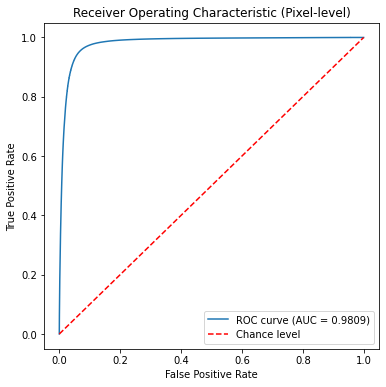

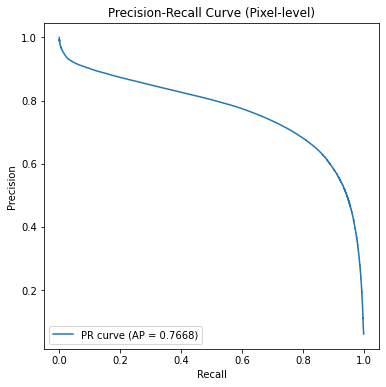

ROC AUC: 0.9809
Average Precision: 0.7668


In [21]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from tensorflow.keras.models import load_model
from tensorflow.keras import backend as K
import tensorflow as tf

# Define the missing functions that were used to create the model
def get_boundary_mask(y_true, kernel_size=5):
    """Helper function to detect boundary regions of the mask with wider boundary area"""
    # Dilate
    dilated = tf.nn.max_pool2d(y_true, ksize=kernel_size, strides=1, padding='SAME')
    # Erode
    eroded = -tf.nn.max_pool2d(-y_true, ksize=kernel_size, strides=1, padding='SAME')
    
    # Boundary is regions that are in dilated but not in eroded
    boundary = tf.cast(tf.logical_and(
        tf.logical_or(dilated > 0.5, y_true > 0.5),
        tf.logical_or(eroded < 0.5, y_true < 0.5)
    ), tf.float32)
    
    return boundary

def weighted_dice_loss(y_true, y_pred, smooth=1.0):
    """Enhanced weighted dice loss with stronger emphasis on boundaries and foreground"""
    # Get boundary regions
    boundary = get_boundary_mask(y_true, kernel_size=5)
    
    # Create weights - higher weight for foreground (15x) and boundaries (20x)
    weights = tf.where(boundary > 0.5, 
                      tf.ones_like(y_true) * 20.0,  # boundary weight (increased)
                      tf.where(y_true > 0.5, 
                              tf.ones_like(y_true) * 15.0,  # foreground weight (increased)
                              tf.ones_like(y_true)))  # background weight
    
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    weights_f = K.flatten(weights)
    
    # Weight the pixel-wise multiplication
    weighted_intersection = K.sum(weights_f * y_true_f * y_pred_f)
    
    # Weight the sums
    weighted_sum = K.sum(weights_f * y_true_f) + K.sum(weights_f * y_pred_f)
    
    # Calculate weighted Dice coefficient
    weighted_dice = (2.0 * weighted_intersection + smooth) / (weighted_sum + smooth)
    
    return 1.0 - weighted_dice

def weighted_tversky_loss(y_true, y_pred, alpha=0.8, beta=0.2, smooth=1.0):
    """
    Weighted Tversky loss with stronger boundary emphasis and higher alpha
    """
    # Get boundary regions
    boundary = get_boundary_mask(y_true, kernel_size=5)
    
    # Basic foreground weighting with boundary enhancement
    weights = tf.where(boundary > 0.5,
                       tf.ones_like(y_true) * 20.0,  # boundary weight (increased)
                       tf.where(y_true > 0.5,
                               tf.ones_like(y_true) * 15.0,  # foreground weight (increased)
                               tf.ones_like(y_true)))  # background weight
    
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    weights_f = K.flatten(weights)
    
    # Weight the true positives
    weighted_tp = K.sum(weights_f * y_true_f * y_pred_f)
    
    # Weight false negatives more heavily to improve recall
    weighted_fn = K.sum(weights_f * y_true_f * (1.0 - y_pred_f))
    
    # Weight false positives to improve precision
    weighted_fp = K.sum(weights_f * (1.0 - y_true_f) * y_pred_f)
    
    # Calculate weighted Tversky index with increased alpha to prioritize recall
    weighted_tversky = (weighted_tp + smooth) / (weighted_tp + alpha * weighted_fn + beta * weighted_fp + smooth)
    
    return 1.0 - weighted_tversky

def weighted_ptc_simple_loss(y_true, y_pred):
    """
    Enhanced combined loss for segmentation with greater emphasis on boundary awareness
    """
    # Get components
    dice_component = weighted_dice_loss(y_true, y_pred)
    tversky_component = weighted_tversky_loss(y_true, y_pred, alpha=0.8, beta=0.2)  # Modified alpha/beta
    
    # Add focal component for hard examples
    epsilon = K.epsilon()
    y_pred_clipped = K.clip(y_pred, epsilon, 1.0 - epsilon)
    
    # Focal parameters - increased gamma for harder examples
    focal_gamma = 3.0  # Increased from 2.0
    
    # BCE with higher weight (8x) for positive class pixels (increased from 5x)
    bce = -(8.0 * y_true * K.log(y_pred_clipped) + (1.0 - y_true) * K.log(1.0 - y_pred_clipped))
    
    # Add focal weighting for hard examples
    focal_weight = K.pow(tf.abs(y_true - y_pred_clipped), focal_gamma)
    focal_bce = focal_weight * bce
    bce_component = K.mean(focal_bce)
    
    # Re-balanced combination - higher weight on dice and tversky for thin structures
    return 0.5 * dice_component + 0.4 * tversky_component + 0.1 * bce_component

# Custom metrics
def dice_coef(y_true, y_pred, smooth=1.0):
    """Dice coefficient metric"""
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def iou(y_true, y_pred, smooth=1):
    """IoU metric (Jaccard index)"""
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)

def accuracy(y_true, y_pred):
    """Pixel-wise accuracy"""
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(tf.round(y_pred))
    correct_predictions = tf.equal(y_true_f, y_pred_f)
    return tf.reduce_mean(tf.cast(correct_predictions, tf.float32))

def precision(y_true, y_pred):
    """Precision metric"""
    y_pred_f = tf.keras.backend.flatten(tf.round(y_pred))
    y_true_f = tf.keras.backend.flatten(y_true)
    true_positives = tf.reduce_sum(y_true_f * y_pred_f)
    predicted_positives = tf.reduce_sum(y_pred_f)
    return true_positives / (predicted_positives + tf.keras.backend.epsilon())

def recall(y_true, y_pred):
    """Recall metric (sensitivity)"""
    y_pred_f = tf.keras.backend.flatten(tf.round(y_pred))
    y_true_f = tf.keras.backend.flatten(y_true)
    true_positives = tf.reduce_sum(y_true_f * y_pred_f)
    possible_positives = tf.reduce_sum(y_true_f)
    return true_positives / (possible_positives + tf.keras.backend.epsilon())

def specificity(y_true, y_pred):
    """Specificity metric"""
    y_pred_f = tf.keras.backend.flatten(tf.round(y_pred))
    y_true_f = tf.keras.backend.flatten(y_true)
    true_negatives = tf.reduce_sum((1 - y_true_f) * (1 - y_pred_f))
    possible_negatives = tf.reduce_sum(1 - y_true_f)
    return true_negatives / (possible_negatives + tf.keras.backend.epsilon())

def f1_score(y_true, y_pred):
    """F1 Score metric"""
    prec = precision(y_true, y_pred)
    rec = recall(y_true, y_pred)
    return 2 * ((prec * rec) / (prec + rec + tf.keras.backend.epsilon()))


# Specify batch size
batch_size = 32  # Adjust as needed

# Set the TFRecord directory
TFRECORD_DIR = "/orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Data/TFRecords_Zoom2"

# Create the test dataset
test_dataset = create_dataset(os.path.join(TFRECORD_DIR, "test.tfrecord"), batch_size=batch_size)

# Load the model with custom objects
# Update your custom_objects dictionary to include all metrics
custom_objects = {
    'weighted_ptc_simple_loss': weighted_ptc_simple_loss,
    'weighted_dice_loss': weighted_dice_loss,
    'weighted_tversky_loss': weighted_tversky_loss,
    'get_boundary_mask': get_boundary_mask,
    # Add these metrics
    'dice_coef': dice_coef,
    'iou': iou,
    'accuracy': accuracy,
    'precision': precision,
    'recall': recall,
    'specificity': specificity,
    'f1_score': f1_score
}

# Then load the model with the complete custom_objects dictionary
model = load_model('best_model.h5', custom_objects=custom_objects)

model = load_model('best_model.h5', custom_objects=custom_objects)

# Use the model to predict on the test set
y_pred_list = []
y_true_list = []

for images, masks in test_dataset:
    # Predict probabilities
    pred_probs = model.predict(images)
    
    # Store predictions and ground truth
    y_pred_list.append(pred_probs)
    y_true_list.append(masks.numpy())

# Concatenate all batches
y_pred_all = np.concatenate(y_pred_list, axis=0)  # shape: [num_samples, H, W, 1]
y_true_all = np.concatenate(y_true_list, axis=0)  # shape: [num_samples, H, W, 1]

# Flatten to 1D (pixel-level)
y_pred_flat = y_pred_all.flatten()
y_true_flat = y_true_all.flatten()

# Compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_true_flat, y_pred_flat)
roc_auc = auc(fpr, tpr)

# Plot
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'r--', label='Chance level')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (Pixel-level)')
plt.legend(loc='lower right')
plt.savefig('pixel_level_roc.png')
plt.show()

# Also compute precision-recall curve which can be more informative for imbalanced datasets
precision, recall, _ = precision_recall_curve(y_true_flat, y_pred_flat)
avg_precision = average_precision_score(y_true_flat, y_pred_flat)

# Plot precision-recall curve
plt.figure(figsize=(6, 6))
plt.plot(recall, precision, label=f'PR curve (AP = {avg_precision:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (Pixel-level)')
plt.legend(loc='lower left')
plt.savefig('pixel_level_pr.png')
plt.show()

# Print summary statistics
print(f"ROC AUC: {roc_auc:.4f}")
print(f"Average Precision: {avg_precision:.4f}")